<a href="https://colab.research.google.com/github/OmRohamare/stats_for_data/blob/main/Distributions.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:

import pandas as pd                    # load data, mean(), median(), mode()
import numpy as np                     # mean, median, weighted average
from scipy import stats                # trim_mean, gmean, hmean, mode
import matplotlib.pyplot as plt        # visualization
import seaborn as sns

In [3]:
cleaned = pd.read_csv('/content/drive/MyDrive/statsdata/house_sales_cleaned.csv', sep='\t')
cleaned

,DocumentDate,SalePrice,PropertyID,PropertyType,ym,zhvi_px,zhvi_idx,AdjSalePrice,NbrLivingUnits,SqFtLot,...,Bathrooms,Bedrooms,BldgGrade,YrBuilt,YrRenovated,TrafficNoise,LandVal,ImpsVal,ZipCode,NewConstruction
0,2014-09-16,280000,1000102,Multiplex,2014-09-01,405100,0.930836,300805.0,2,9373,...,3.00,6,7,1991,0,0,70000,229000,98002,False
1,2006-06-16,1000000,1200013,Single Family,2006-06-01,404400,0.929228,1076162.0,1,20156,...,3.75,4,10,2005,0,0,203000,590000,98166,True
2,2007-01-29,745000,1200019,Single Family,2007-01-01,425600,0.977941,761805.0,1,26036,...,1.75,4,8,1947,0,0,183000,275000,98166,False
3,2008-02-25,425000,2800016,Single Family,2008-02-01,418400,0.961397,442065.0,1,8618,...,3.75,5,7,1966,0,0,104000,229000,98168,False
4,2013-03-29,240000,2800024,Single Family,2013-03-01,351600,0.807904,297065.0,1,8620,...,1.75,4,7,1948,0,0,104000,205000,98168,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
22662,2011-04-08,325000,9842300710,Single Family,2011-04-01,318700,0.732307,443803.0,1,5468,...,1.75,3,7,1951,0,0,201000,172000,98126,False
22663,2007-09-28,1580000,9845500010,Single Family,2007-09-01,433500,0.996094,1586196.0,1,23914,...,4.50,4,11,2000,0,1,703000,951000,98040,False
22664,2012-07-09,165000,9899200010,Single Family,2012-07-01,325300,0.747472,220744.0,1,11170,...,1.00,4,6,1971,0,0,92000,130000,98055,False
22665,2006-05-26,315000,9900000355,Single Family,2006-05-01,400600,0.920496,342207.0,1,6223,...,2.00,3,7,1939,0,0,103000,212000,98166,False


#1.Empirical

In [5]:
numeric_cols = cleaned.select_dtypes(include='number').columns.tolist()
print(numeric_cols)


['SalePrice', 'PropertyID', 'zhvi_px', 'zhvi_idx', 'AdjSalePrice', 'NbrLivingUnits', 'SqFtLot', 'SqFtTotLiving', 'SqFtFinBasement', 'Bathrooms', 'Bedrooms', 'BldgGrade', 'YrBuilt', 'YrRenovated', 'TrafficNoise', 'LandVal', 'ImpsVal', 'ZipCode']


# 1.Histogram


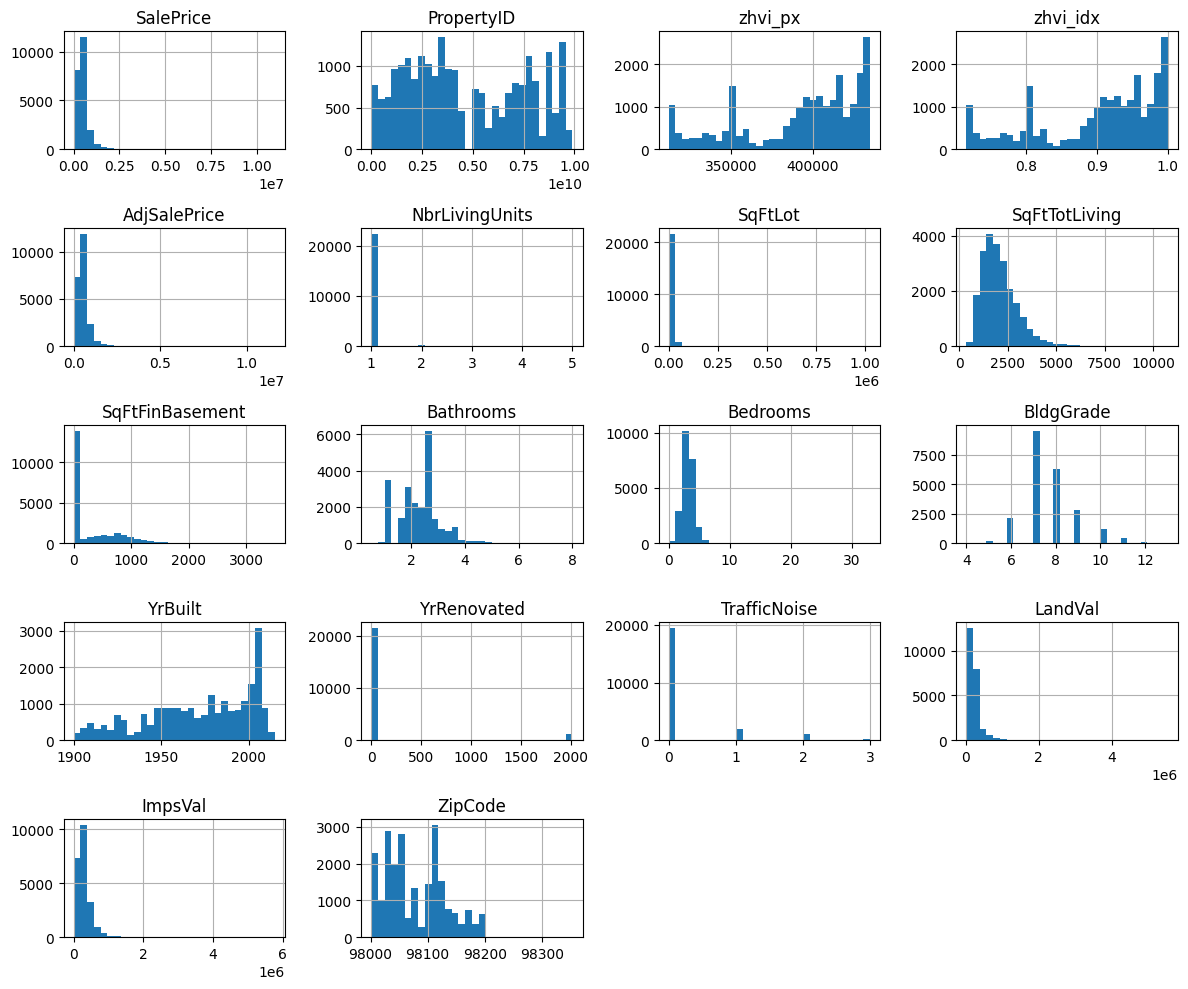

In [8]:
# Generates individual subplots automatically for all numeric columns
cleaned.hist(bins=30, figsize=(12, 10))

plt.tight_layout() # Prevents overlapping labels
plt.show()


# 2.KDE
A KDE plot (Kernel Density Estimate plot) is a chart that shows the probability distribution of a continuous variable using a smooth, continuous curve instead of discrete bars

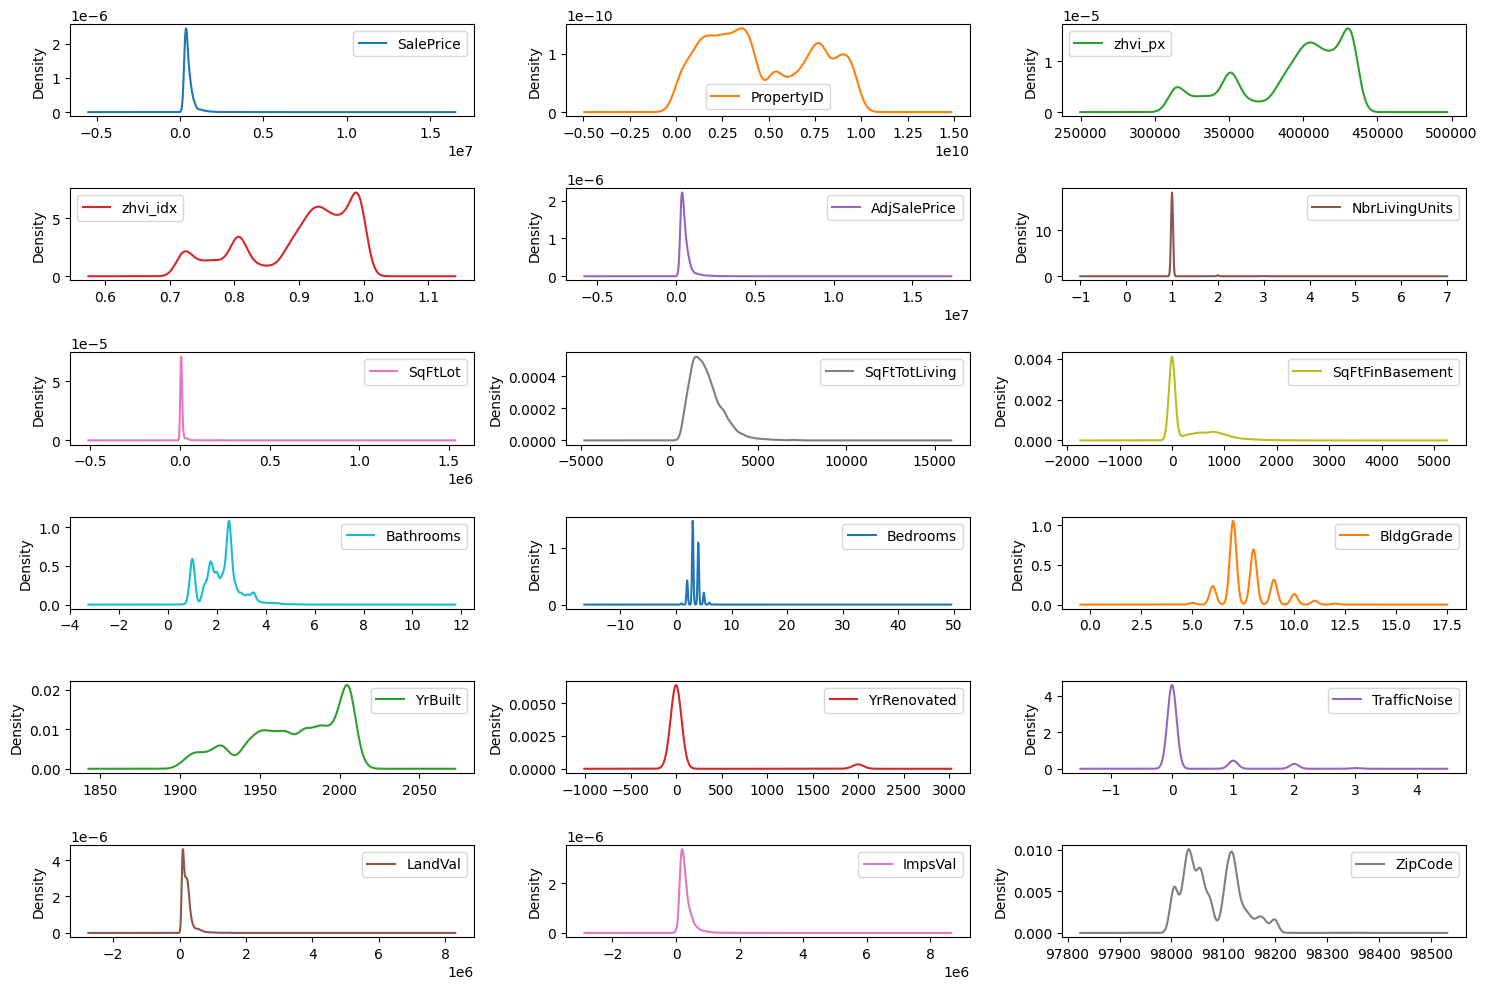

In [13]:
# Generate individual kernel density estimation (KDE) plots
# for every numeric column in the 'cleaned' DataFrame
cleaned.plot(
    kind='density',      # Specifies density (KDE) plots to visualize distributions
    subplots=True,       # Creates a separate subplot for each column
    layout=(-1, 3),      # Organizes subplots into a grid with 3 columns (-1 calculates rows automatically)
    sharex=False,        # Gives each subplot its own independent X-axis scale
    figsize=(15, 10)     # Sets the overall width and height of the figure window
)

# Automatically adjust subplot parameters to prevent overlapping labels/titles
plt.tight_layout()

# Render and display the final visualization window
plt.show()

# Empirical Cumulative Distribution Function (ECDF):
Displays the exact proportion or count of data observations falling at or below each unique value on a non-decreasing step curve

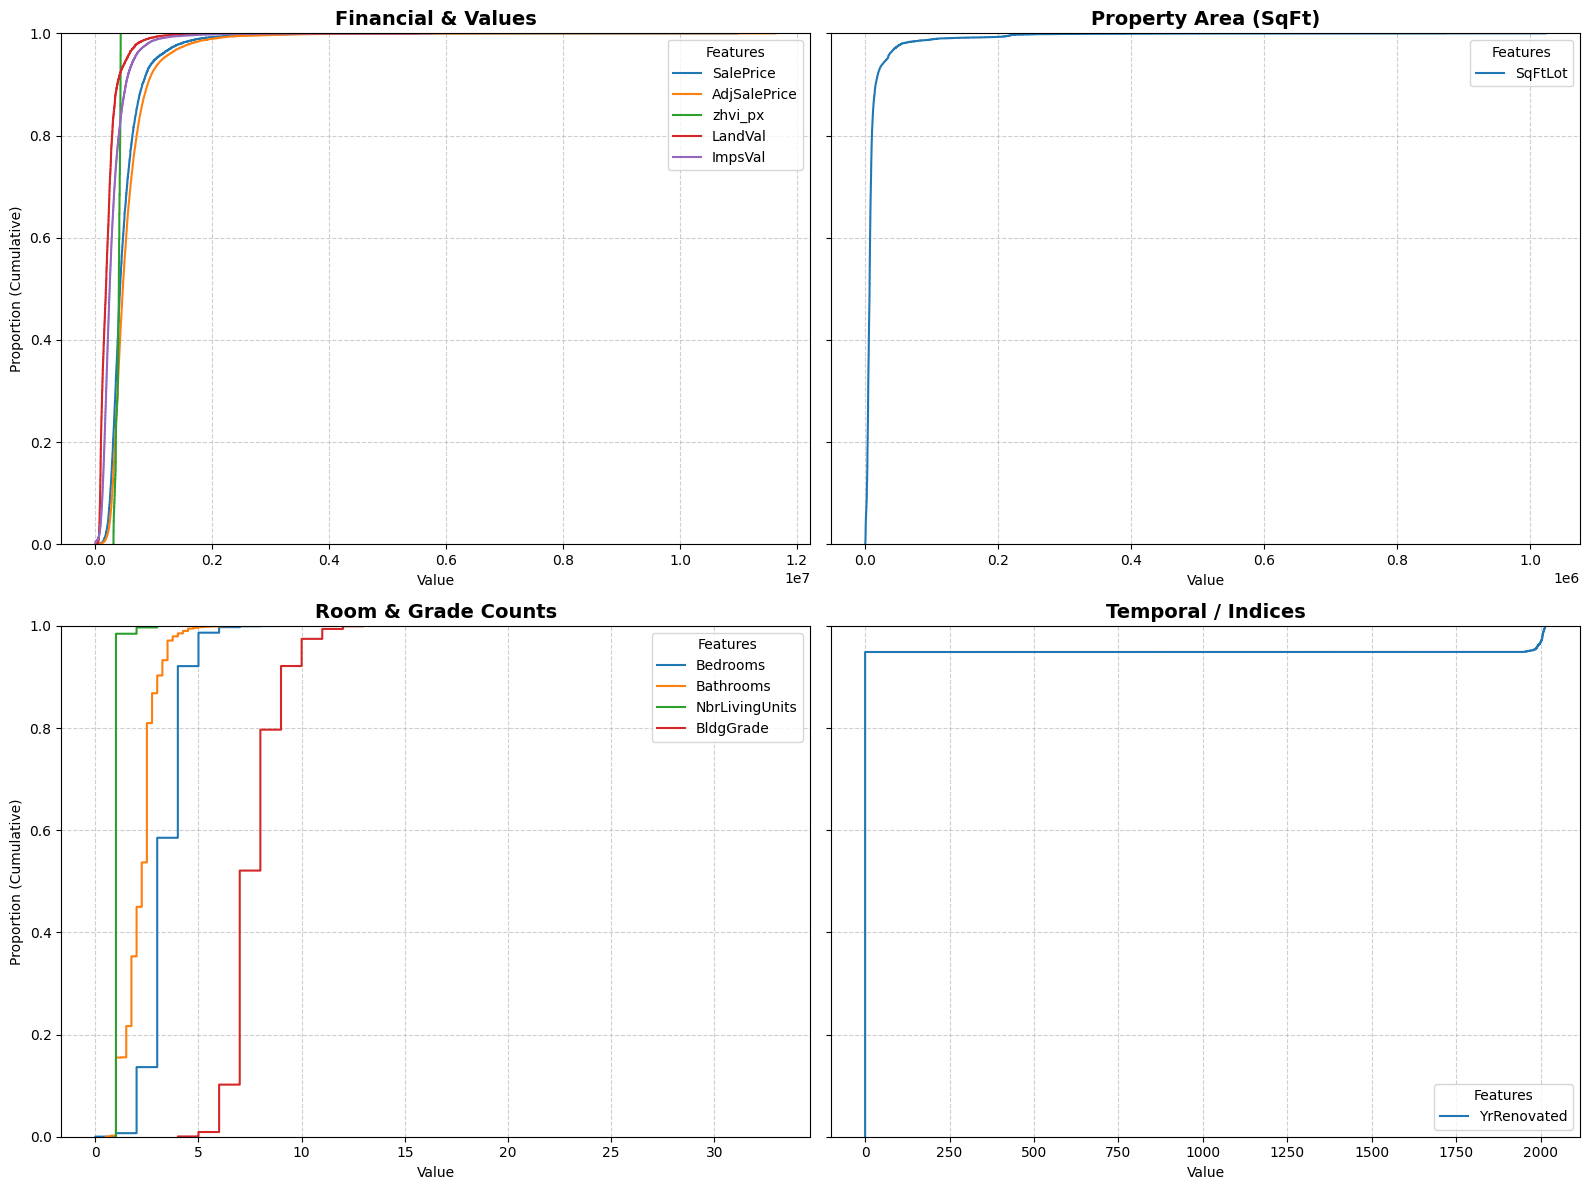

In [29]:
#Defining feature groups for readibility
price_cols= ["SalePrice","AdjSalePrice","zhvi_px","LandVal","ImpsVal"]
space_cols=["SqFtLot","SqFtToLiving","SqFtinBasement"]
time_cols=["YrBulit","YrRenovated","zhvu_idx"]
rooms_cols=["Bedrooms","Bathrooms","NbrLivingUnits","BldgGrade"]

all_groups=[price_cols,space_cols,room_cols,time_cols]
titel=["Finacial & values", "Property Area (SqFt)",
       "Room and grade counts","Temporal/Indices"]

#Creating a 2x2 gird of subplots
fig, axes = plt.subplots(2, 2, figsize=(16, 12),sharey=True)
axes=axes.flatten()

for i, group in enumerate(all_groups):
  ax=axes[i]
  # Plot each column in the group (ignores missing columns gracefully)
  for col in group:
      if col in cleaned.columns:
         sns.ecdfplot(data=cleaned, x=col, ax=ax, label=col)

  ax.set_title(titles[i], fontsize=14, fontweight='bold')
  ax.set_xlabel("Value")
  ax.set_ylabel("Proportion (Cumulative)")
  ax.legend(title="Features")
  ax.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()


#Box Plot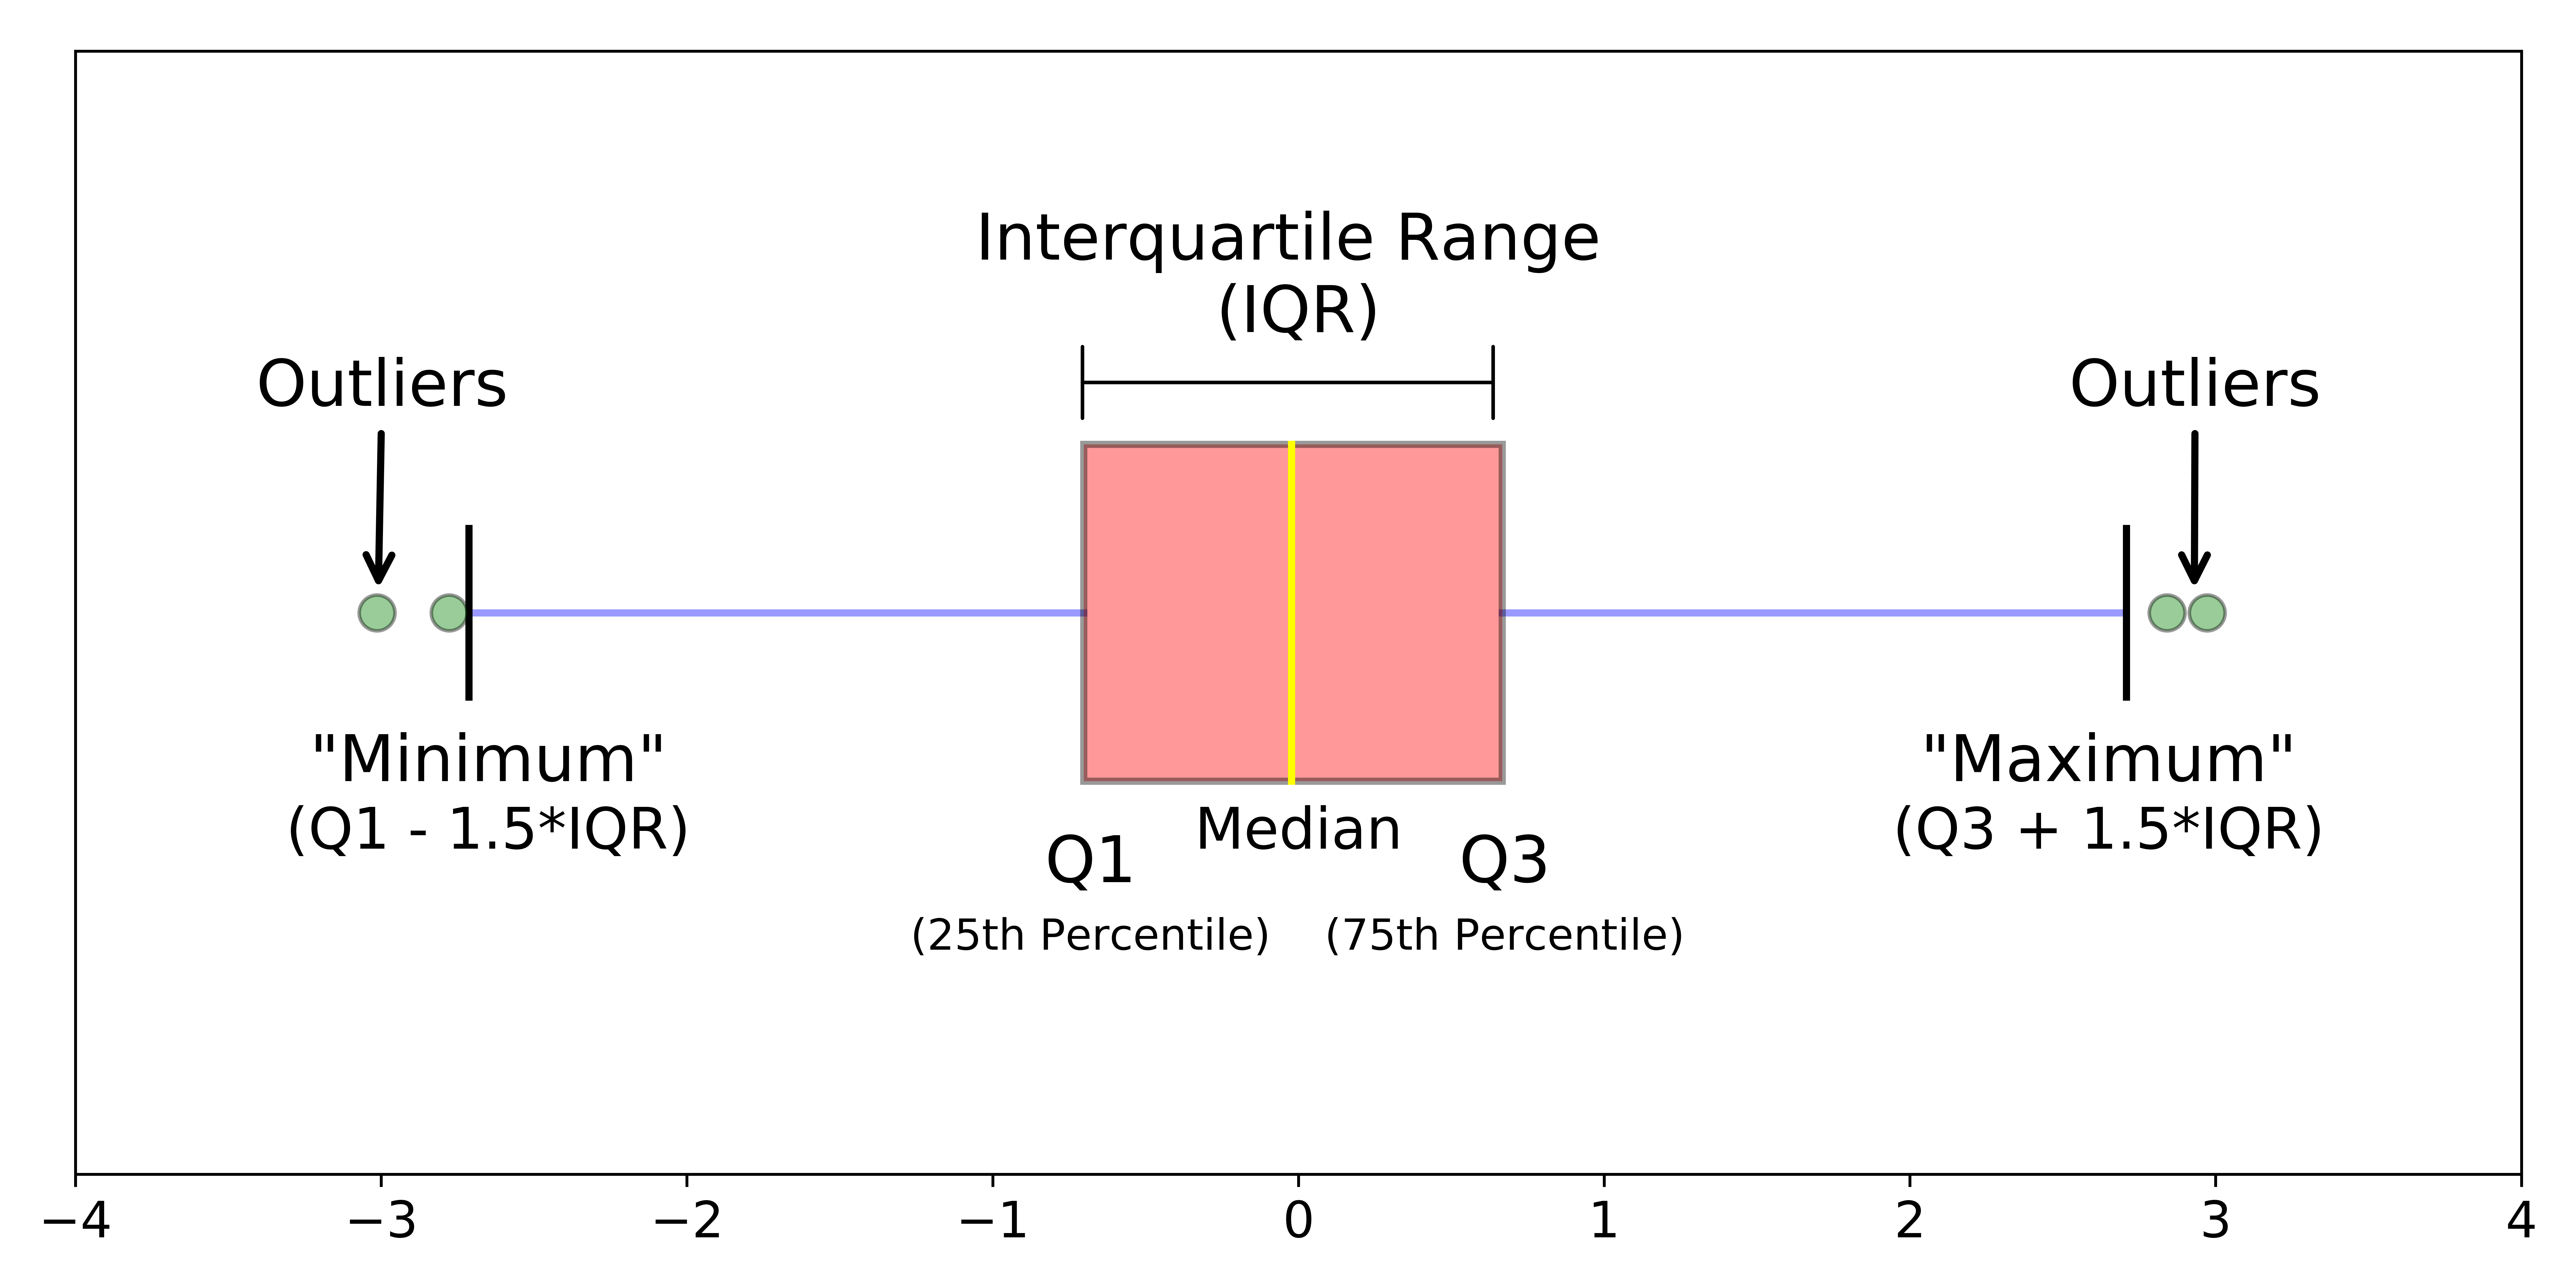

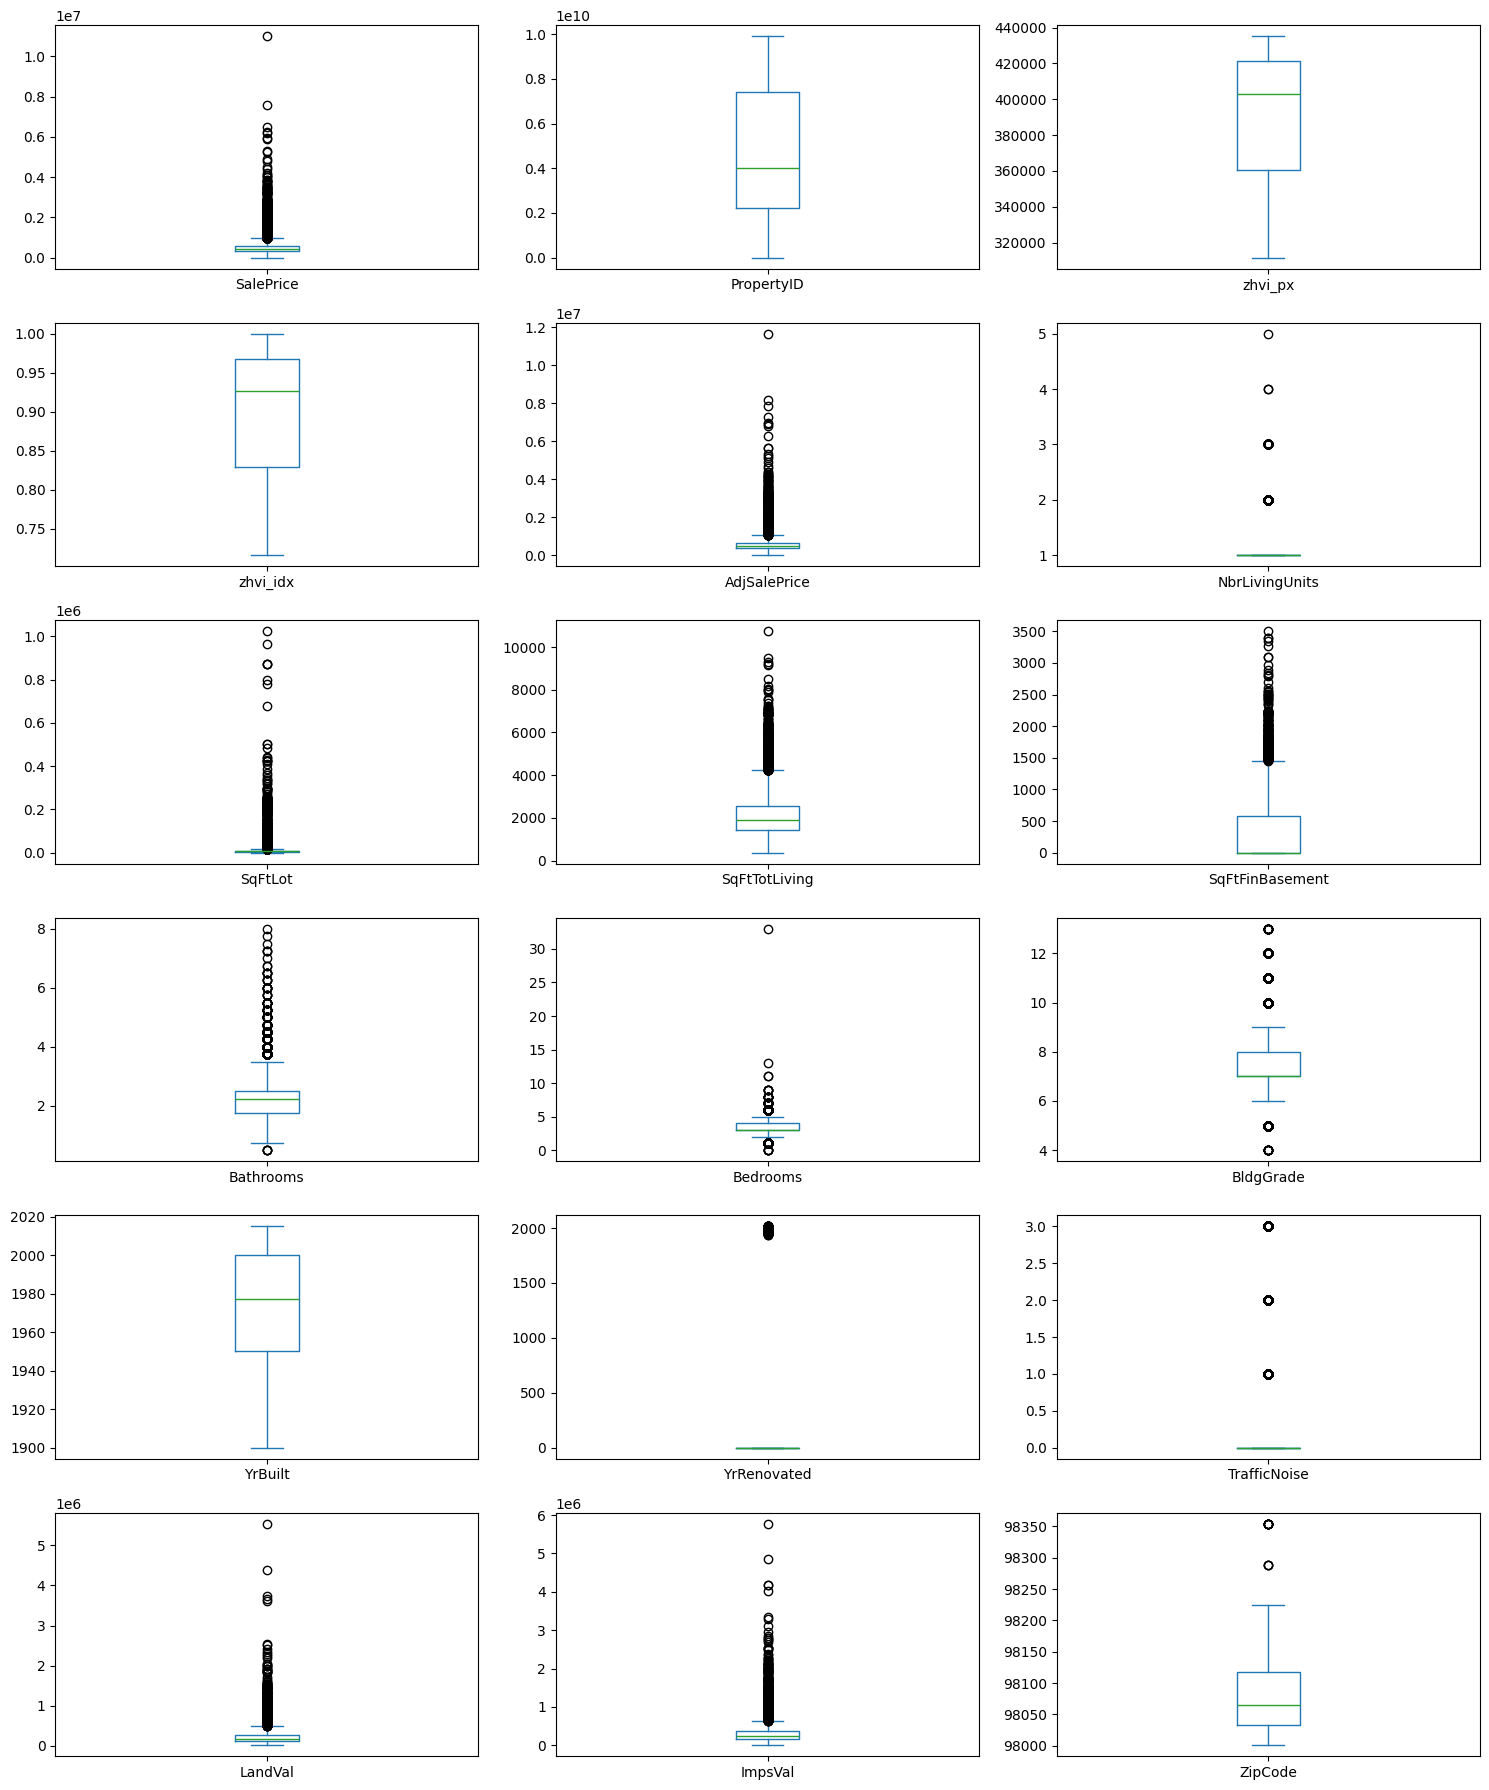

In [37]:
# 1. Calculate the number of rows dynamically
num_cols = len(cleaned.select_dtypes(include=['number']).columns)
num_rows = (num_cols + 2) // 3  # Rounds up to fit all columns into 3 columns

# 2. Plot with a valid positive integer layout
cleaned.plot(
    kind='box',
    subplots=True,
    layout=(num_rows, 3),
    sharex=False,
    figsize=(15, 3 * num_rows)  # Scales the height dynamically based on rows
)

plt.tight_layout()
plt.show()


#Violin Plot


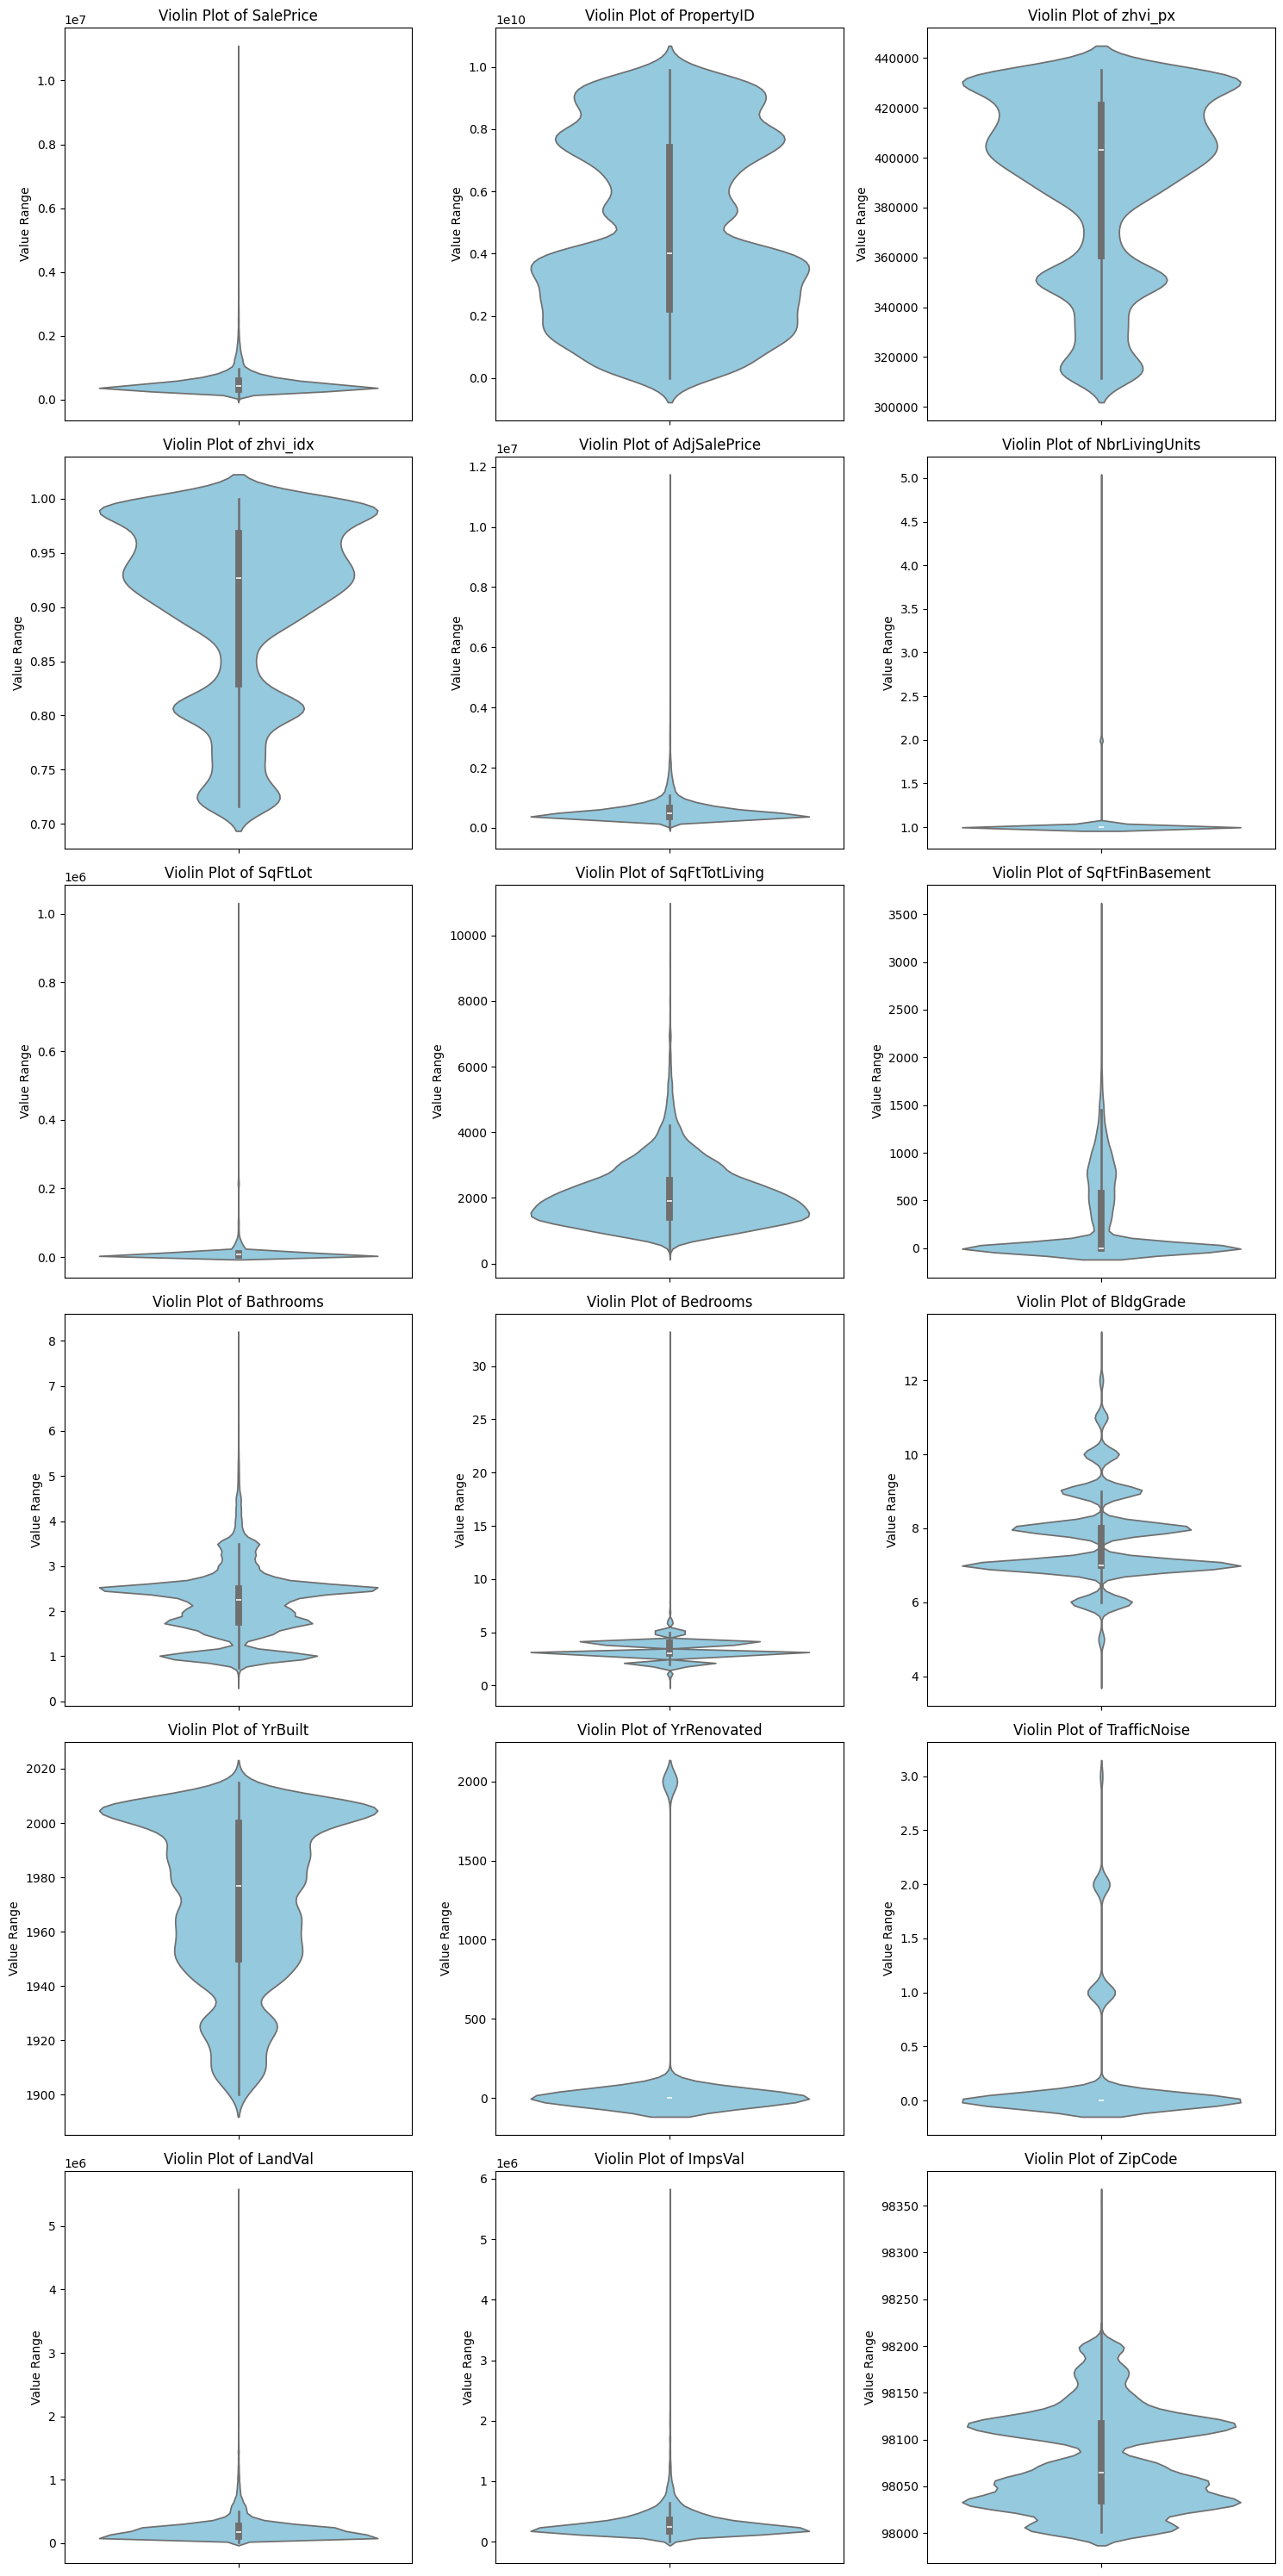

In [45]:
# 1. Isolate the numeric columns from your DataFrame
num_plots = len(numeric_cols)

# 2. Dynamically set up a grid layout (3 columns per row)
ncols = 3
nrows = (num_plots + ncols - 1) // ncols

# Fixed: Added multiplication operator (*) for figsize height calculation
fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(15, 5 * nrows))

# Flatten axes array so we can index it easily using a single loop
axes = axes.flatten()

# 3. Loop through columns and plot each on its own subplot
for i, col in enumerate(numeric_cols):
    # Fixed: Replaced 'palette' with 'color' to avoid the deprecation warning
    sns.violinplot(data=cleaned, y=col, ax=axes[i], color="skyblue")
    axes[i].set_title(f"Violin Plot of {col}")
    axes[i].set_ylabel("Value Range")

# 4. Remove any unused empty subplots if the grid isn't perfectly full
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()